# AOE 5154 Final Project
Ted Balabanski

The following is code developed for the final project for AOE 5154. This includes the primary analysis.

In [1]:
# dependencies
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import pickle as pkl
from IPython.display import HTML
from tqdm import tqdm

# set the basepath to data
DATA_BASE_PATH = os.path.abspath("../data/")

## Part 0. Data Loading and Preprocessing

First, load in the data and do some elementary cleaning

In [2]:
filename = "2d_conc_wind616.pkl"
with open(os.path.join(DATA_BASE_PATH, filename), 'rb') as fi:
    data = np.array(pkl.load(fi))

# add the concentrations from the five sources together to analyze as one
data = np.add.reduce(data, axis=0)

print(f"read {filename} with shape {data.shape}")

read 2d_conc_wind616.pkl with shape (3052, 99, 33)


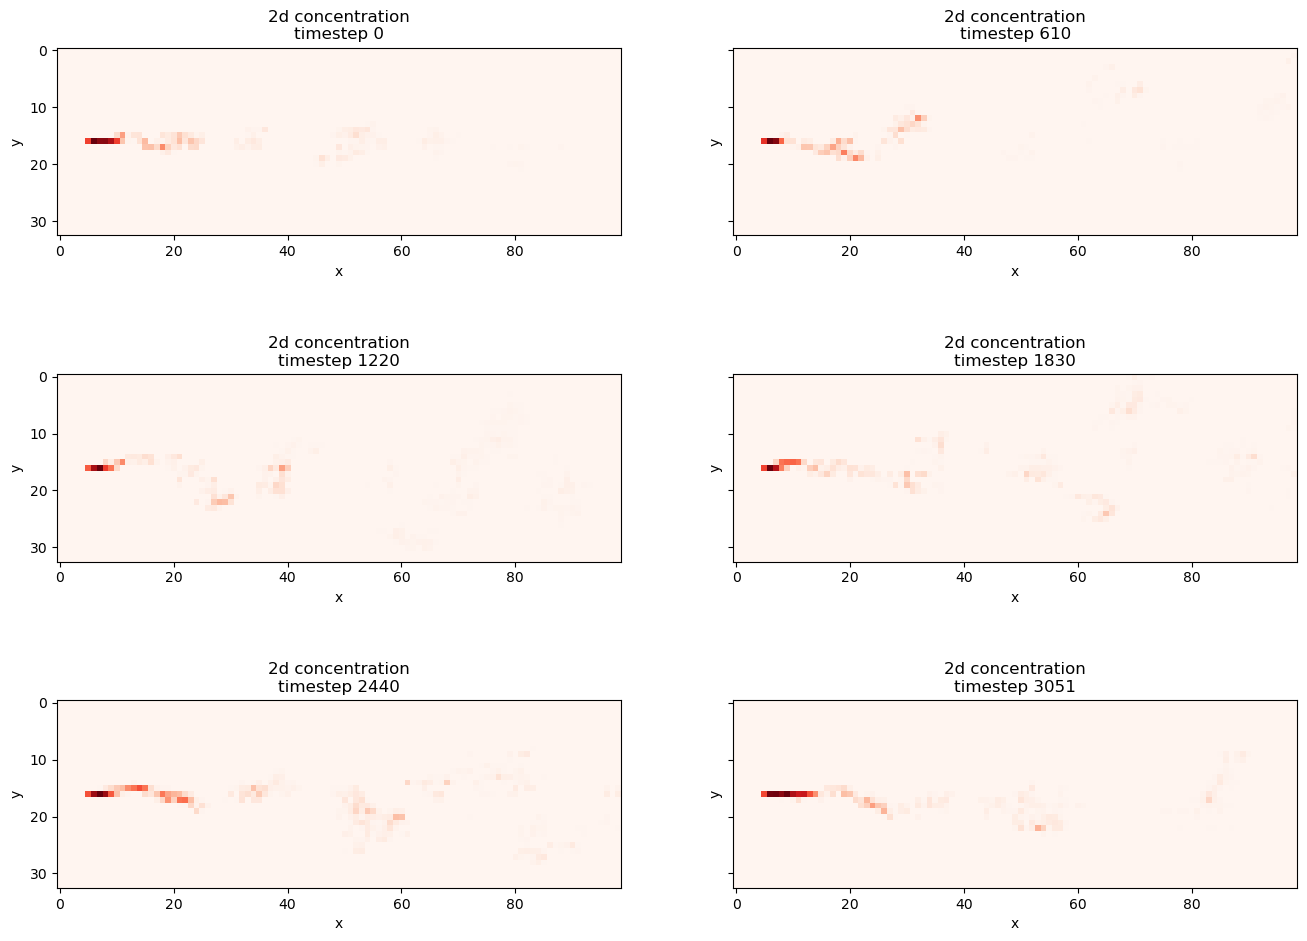

In [3]:
# plot a couple of timesteps of the 2d concentration data
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharey=True)
ax_flat = axes.flatten()
ax_flat[0].set_ylabel("x")

for i, ti in enumerate(np.linspace(0, data.shape[0]-1, 6, endpoint=True, dtype=int)):
    ax = ax_flat[i]

    # format the axes and do some transformations to the data for intuitive plotting
    ax.imshow(np.flip(data[ti, :, :].transpose(), axis=1), cmap='Reds')
    ax.set_title(f"2d concentration\ntimestep {ti}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

file_save = os.path.join(DATA_BASE_PATH, "..", "figs", "2dconc616-overview.png")
plt.savefig(file_save, dpi=600, bbox_inches='tight')
plt.show()

Create a short animation to show the flow

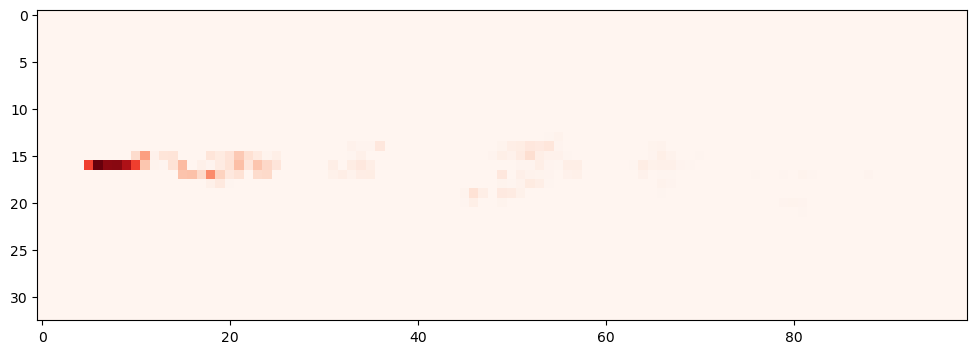

In [25]:
# initialize the plot
fig, ax = plt.subplots(figsize=(12,8))
conc = ax.imshow(np.flip(data[0, :, :].transpose(), axis=1), cmap='Reds')

# define the function to update the plot
def update(frame):
    return ax.imshow(np.flip(data[frame, :, :].transpose(), axis=1), cmap='Reds')

ani = animation.FuncAnimation(fig=fig, func=update, frames=data.shape[0] // 20, interval=20)
HTML(ani.to_jshtml())

Plot time-averaged concentrations profiles (in the transverse, $y$, direction) at various different positions in the streamwise ($x$) direction.

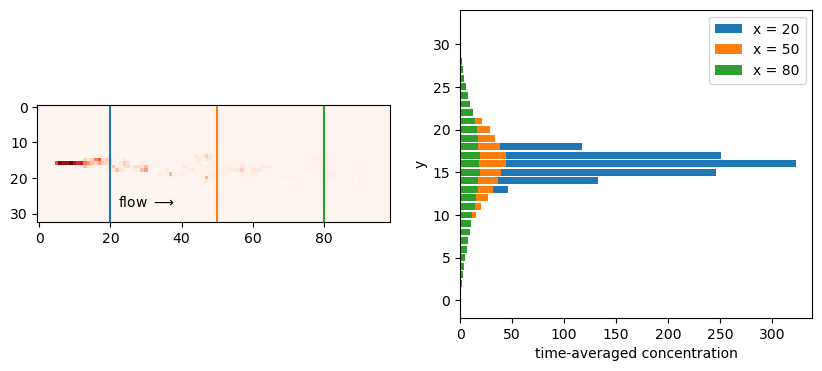

In [4]:
# flip the data so that the downstream points are greater in x
data_flip = np.flip(data, axis=1)

# determine the x-positions for the plotting
x_values = [20, 50, 80]

# build the plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.imshow(data_flip[100, :, :].transpose(), cmap='Reds')

# iterate through each of the x-values
for x in x_values:
    ax1.plot([x, x], [0, data.shape[2]-1])
    ax2.barh(y = np.arange(0, data_flip.shape[2], step=1),
             width = np.mean(data_flip[:, x, :], axis=0), 
             label = f"x = {x}")

# format the axes and add some text
ax1.text(22, 28, r"flow $\longrightarrow$", parse_math=True)
ax2.set_ylabel('y')
ax2.set_xlabel('time-averaged concentration')
ax2.legend()

# save and show the plot
file_save = os.path.join(DATA_BASE_PATH, "..", "figs", "transverse-2dconc616.png")
plt.savefig(file_save, dpi=600, bbox_inches='tight')
plt.show()

## Part 1. Correlations

Before beginning to calculate correlations, we calculate the mean-free concentration field

In [20]:
# calculate the fluctuating component
cbar = np.mean(data_flip, axis=0)
cf = np.zeros_like(data_flip)
for i in range(data_flip.shape[0]):
    cf[i, :, :] = np.subtract(data_flip[i, :, :], cbar)

print(f"mean-free concentration shape: {cf.shape}")

mean-free concentration shape: (3052, 99, 33)


### Part 1.1. Spatial Autocorrelation

Now, determine how the spatial structure of the flow looks like on a correlative basis. In particular, we are interested in the spatial autocorrelation $R_{CC}(\xi, \eta) = E[C(x + \xi, y + \eta, t) C(x, y, t)]$

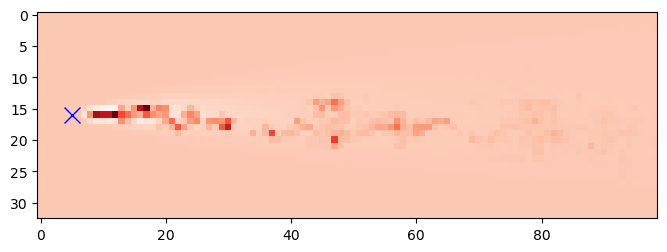

In [26]:
# choose the anchor point right where the sources are
anch_ix1, anch_ix2 = 5, 16

# plot the anchor point and the 
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.imshow(cf[100, :, :].transpose(), cmap='Reds')
ax.plot(anch_ix1, anch_ix2, marker='x', markersize=12, color='blue')

plt.show()

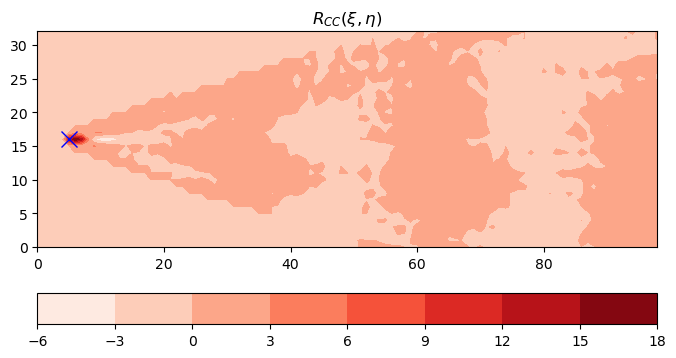

In [106]:
# calculate the zero-mean data and the spatial autocorrelation
Rcc = np.mean(np.multiply(cf.T, cf[:, anch_ix1, anch_ix2].T), axis=2) * (1 / (cf.shape[0] - 1))

# intitialize the plot
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
im = ax.contourf(Rcc, cmap='Reds')
ax.plot(anch_ix1, anch_ix2, marker='x', markersize=12, color='blue')
ax.set_title(r"$R_{CC}(\xi, \eta)$")
fig.colorbar(im, ax=ax, location='bottom')

# save and show the plot
file_save = os.path.join(DATA_BASE_PATH, "..", "figs", "spatial-autocorr-616.png")
plt.savefig(file_save, dpi=600, bbox_inches='tight')
plt.show()

### Part 1.2. Power Spectral Density

Calculate the power spectral density at a point downstream

In [47]:
# code developed from my solutions to homework 4
def power_spectral_density(x, fs):
    # determine the power spectral density of a signal and a sampling frequency
    # the signal should be one dimensional with samples in time
    n = x.size
    
    # calculate the fft of the signal
    # use only the nonnegative frequency components
    spec_f = np.fft.rfft(x)
    
    # determine the halfway point and calculate the autospectral density
    ihalf = int((n + 1)/2) if n % 2 != 0 else int((n / 2) - 1)
    G = (np.abs(spec_f[:ihalf]) ** 2) * (1 / n / fs)
    f = np.arange(ihalf) * fs / n
    
    # convert to a one sided psd by doubling the appropriate mode
    if n % 2 == 0:
        G[1:-1] *= 2
    else:
        G[1:] *= 2
        
    return G, f

ds_anch_ix1, ds_anch_ix2 = 50, 15 # downstream point anchor
fs = 1/150 # sampling rate of the data
Gcc, f = power_spectral_density(cf[:, ds_anch_ix1, ds_anch_ix2], fs)

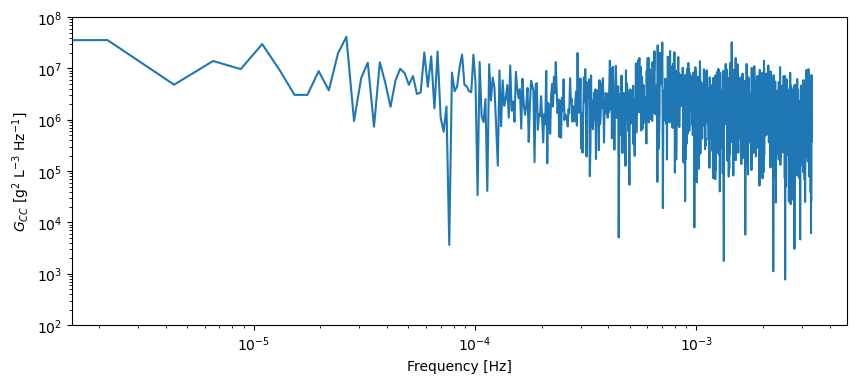

In [50]:
# plot the power spectral density
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(f, Gcc)

# format the plot
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("$G_{C C}$ [g$^2$ L$^{-3}$ Hz$^{-1}$]")
ax.set_ylim(1e2, 1e8)
plt.show()

## Part 2. POD Mode Analysis

Calculate the POD modes for the flow field. Much of this is adapted from the code I developed for Homework 3.

In [84]:
# format them as snapshots
cpod = cf.reshape(cf.shape[0], -1).T

# calculate the autocovariance matricies
Rc = np.matmul(np.transpose(cpod), cpod)

# display the resulting shapes
print(f"snapshots shape:\t{cpod.shape}")
print(f"Rc shape:\t\t{Rc.shape}")

snapshots shape:	(3267, 3052)
Rc shape:		(3052, 3052)


In [85]:
eigs1, eigvs1 = np.linalg.eigh(Rc)

### Part 2.1. Calculate relative energy of the modes

In [86]:
# sort the eigenvalues and vectors
inds1 = np.argsort(eigs1)[::-1]
eigs1_sorted = np.maximum(0.0, eigs1[inds1])
eigvs1_sorted = eigvs1[:,inds1]

# calculate the relative energy of each mode
rel_e1 = eigs1_sorted / np.sum(eigs1_sorted)
cum_e1 = np.cumsum(rel_e1)

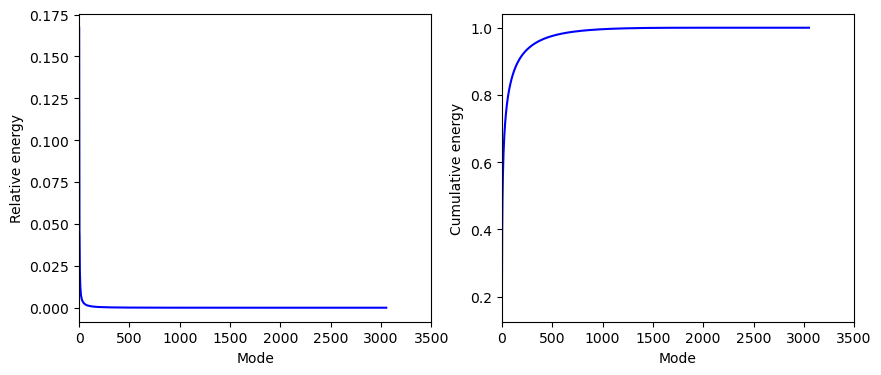

In [107]:
# plot the result
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(rel_e1, color='b')
ax2.plot(cum_e1, color='b')

# format the plot
ax1.set_ylabel("Relative energy")
ax1.set_xlabel("Mode")
ax1.set_xlim(0, 3500)
ax2.set_ylabel("Cumulative energy")
ax2.set_xlabel("Mode")
ax2.set_xlim(0, 3500)

# save and show the plot
file_save = os.path.join(DATA_BASE_PATH, "..", "figs", "pod-modes-energy-2dconc616.png")
plt.savefig(file_save, dpi=600, bbox_inches='tight')
plt.show()

### Part 2.2. Calculate and Plot POD modes

In [98]:
# calculate the modes (phi) and the time-dependent coefficients (a)
nt, nx1, nx2 = cf.shape
phi1 = (cpod @ eigvs1_sorted) / np.sqrt(eigs1_sorted)[None, :]
a1 = phi1.T @ cpod
modeshapes1 = phi1.reshape(nx1, nx2, nt)

print(f"(nt, nx1, nx2):\t\t{(nt, nx1, nx2)}")
print(f"phi shape:\t\t{phi1.shape}")
print(f"a shape:\t\t{a1.shape}")
print(f"modeshapes shape:\t{modeshapes1.shape}")

/tmp/ipykernel_151232/4243642262.py:3: RuntimeWarning: divide by zero encountered in divide
  phi1 = (cpod @ eigvs1_sorted) / np.sqrt(eigs1_sorted)[None, :]
/tmp/ipykernel_151232/4243642262.py:3: RuntimeWarning: invalid value encountered in divide
  phi1 = (cpod @ eigvs1_sorted) / np.sqrt(eigs1_sorted)[None, :]


(nt, nx1, nx2):		(3052, 99, 33)
phi shape:		(3267, 3052)
a shape:		(3052, 3052)
modeshapes shape:	(99, 33, 3052)


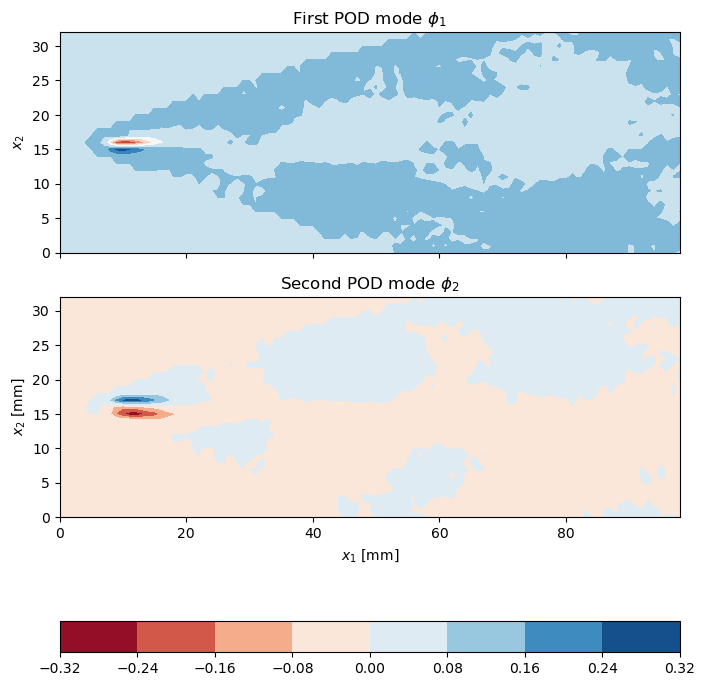

In [108]:
# plot the result
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 9), sharex=True)
im = ax1.contourf(modeshapes1[..., 0].T, cmap='RdBu')
im = ax2.contourf(modeshapes1[..., 1].T, cmap='RdBu')

# format the plot
ax1.set_title(r"First POD mode $\phi_1$")
ax1.set_ylabel(r"$x_2$")
ax2.set_title(r"Second POD mode $\phi_2$")
ax2.set_ylabel(r"$x_2$ [mm]")
ax2.set_xlabel(r"$x_1$ [mm]")
fig.colorbar(im, ax=[ax1, ax2], location='bottom')

# save and show the plot
file_save = os.path.join(DATA_BASE_PATH, "..", "figs", "pod-modes-2dconc616.png")
plt.savefig(file_save, dpi=600, bbox_inches='tight')
plt.show()